# 04. Предварительная оценка RQ1/RQ2: сохранённый пилот 20k

Здесь анализируются **только сохранённые test-вероятности** 28 Pipeline пилота `pilot_20k_5config`. Новых `fit`, `predict`, поиска гиперпараметров, калибратора или fairness-коррекций нет. X, разбиения, параметры, модели и прогнозы остаются неизменными. Ресурсный пилот в эти сравнения не входит.

Выборка обучения пилота: 20 000 клиентов development, пять конфигураций и один refit на пару. Это предварительные результаты Assignment 3, а не замена полного A2 с 20 конфигурациями и пятью повторными обучениями. Остальные development-заявки не использованы при обучении этих моделей.

`RUN_ANALYSIS=False` по умолчанию. Явный запуск анализа безопасен для завершённых bootstrap-checkpoint: уже рассчитанные повторы не пересчитываются. Для просмотра существующих материалов достаточно выполнить конфигурацию и последнюю отчётную ячейку.

In [1]:
from pathlib import Path
import json,sys
import pandas as pd
from IPython.display import display,SVG

ROOT=Path.cwd()
if ROOT.name=='notebooks':
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))

from src.pilot_evaluation import run_evaluation
from src.pilot_evaluation_reporting import export_evaluation_report

PREPARED=ROOT/'data/processed/full'
PILOT_ROOT=ROOT/'artifacts/training/pilot_20k_5config'
PREVIOUS_REPORTS=ROOT/'reports/pilot_20k_5config'
EVALUATION_DIR=PREVIOUS_REPORTS/'evaluation'
N_BOOTSTRAP=1000
SEED=42
RUN_ANALYSIS=False

print('Оценка сохранённых вероятностей; новых fit/predict нет.')
print('Пилот:',PILOT_ROOT)
print('Новые результаты:',EVALUATION_DIR)
print('Запуск анализа включён:',RUN_ANALYSIS)

Оценка сохранённых вероятностей; новых fit/predict нет.
Пилот: artifacts\training\pilot_20k_5config
Новые результаты: reports\pilot_20k_5config\evaluation
Запуск анализа включён: False


## 1. Согласование test-ID и проверка исходных оценок

Вероятности всех 28 сочетаний явно согласуются с сохранёнными test-ID и TARGET. Проверяются уникальность и одинаковый состав 61 503 клиентов, положительный класс `TARGET=1`, отсутствие NaN/inf и диапазон [0,1]. Основная PR-метрика во всём анализе — **PR-AUC (average precision, AP)**, рассчитанная через `average_precision_score`.

AP, ROC-AUC, log-loss и Brier пересчитываются и сравниваются с прежним `rq1_model_comparison.csv`. Несогласие не скрывается: подробности находятся в `existing_metrics_comparison.csv`, а проверки ID — в `alignment_validation.json`. Входные хэши сохраняются до и после анализа. Повторный аудит исходных CSV не выполняется.

Precision с нулевым знаменателем остаётся неопределённой. Например, если модель не предсказывает дефолтов, это не precision=0. Recall и F1 могут быть равны нулю при наличии фактических дефолтов; такие нули сохраняются.

## 2. Общий парный bootstrap и сравнения

Выполняются 1 000 повторов с `default_rng(42)`. Единица ресемплирования — клиент test. Одинаковые клиентские веса на каждом повторе применяются ко всем моделям и уровням. Веса и состояние RNG сохраняются по повтору, поэтому анализ продолжается с checkpoint после прерывания.

95% percentile-интервалы берутся по квантилям 0.025/0.975. Они обозначаются **pointwise, unadjusted, exploratory** и отражают только test-неопределённость фиксированных обученных моделей. Они не учитывают повторное обучение и не являются средним ± SD пяти train-запусков.

Сравнения AP: шесть моделей против LR на Level 4; внутри каждой модели L2/L3/L4 относительно L1, а также L2−L1, L3−L2, L4−L3. Все разности используют уже общие bootstrap-результаты. Bootstrap p-values не вычисляются.

Для ROC-AUC отдельно выполняется парный двухсторонний DeLong: шесть сравнений с LR на Level 4 и Bonferroni в этом семействе. DeLong не является тестом AP. Отсутствие значимой разницы не означает эквивалентность, а правило A2 «не хуже лучшего по AP» не считается формально выполненным. Эти детали анализа зафиксированы сейчас, но не объявляются заранее зарегистрированными.

## 3. Прибыль, fairness, калибровка и ошибки

На Level 4 рассматриваются m=1 и L=1,5,10. Порог фиксирован: 0.5 либо m/(m+L). При L=1 оба совпадают, поэтому результат сохраняется один раз: всего пять сценариев на модель. Одобрение означает `p_default < t`, предсказанный дефолт — `p_default >= t`.

Прибыль на всех заявителей: `mean(approve * ((1-TARGET)*m - TARGET*L))`. Для отклонённых прибыль равна нулю. Используется наблюдённый TARGET, а не ожидаемый исход из вероятности. Approve-all/reject-all — ориентиры. Это условные единицы, не фактическая банковская прибыль; пороги по test не оптимизируются.

Fairness-группы присоединяются по ID: пол и возраст `<25` / `>=25`. Неизвестные группы показаны отдельно; они исключены из бинарных разрывов, но остаются в общих метриках и прибыли. TPR относится к обнаружению фактического дефолта (`TARGET=1`). Оба наблюдаемых **approval-rate gap ≤5 п.п.** проверяются отдельно по полу и возрасту; TPR-gap не подменяет это ограничение. После просмотра результатов предел не ослабляется.

Калибровочные кривые используют десять фиксированных равных интервалов вероятности; последняя правая граница 1 включена. Число наблюдений каждого bin сохранено. Калибратор не обучается. Ошибки сохраняются для всех 28 сочетаний при t=0.5 и для Level 4 при порогах прибыли.

MLP остаётся в таблицах. Фактические `n_iter_`, настройки и предупреждения читаются из сохранённых журналов. Предупреждения всего search+refit нельзя приписывать только выбранному refit. Train loss_ и внешняя log-loss не тождественны; слабое качество само по себе не доказывает переобучение или ошибку предобработки.

## 4. Явный запуск или продолжение анализа — без обучения

Чтобы выполнить анализ, установите `RUN_ANALYSIS=True` в конфигурации и запустите следующую ячейку. Она читает готовые вероятности и продолжает незавершённые bootstrap-повторы; завершённые bootstrap-повторы не вычисляются заново. Проверки входов, точечные сводки и интервалы могут быть обновлены из сохранённых данных и checkpoint. Новые файлы создаются только в `reports/pilot_20k_5config/evaluation/`.

In [2]:
if RUN_ANALYSIS:
    evaluation_result=run_evaluation(PREPARED,PILOT_ROOT,PREVIOUS_REPORTS,EVALUATION_DIR,
                                     n_bootstrap=N_BOOTSTRAP,seed=SEED)
    print('Статус анализа:',evaluation_result.get('status'))
    print('Готово bootstrap-повторов:',evaluation_result.get('completed_bootstrap'))
    print('Новых fit/predict:',evaluation_result.get('new_fit_calls'),evaluation_result.get('new_predict_calls'))
else:
    print('Эта ячейка не запускала расчёты: RUN_ANALYSIS=False.')
    print('Существующие отчёты доступны в следующей ячейке.')

Эта ячейка не запускала расчёты: RUN_ANALYSIS=False.
Существующие отчёты доступны в следующей ячейке.


## 5. Независимый отчёт и материалы для статьи

Эта ячейка зависит только от конфигурации и сохранённых файлов: ей не нужен `evaluation_result`. Она обновляет CSV/LaTeX и читаемый HTML/TXT из рассчитанных результатов. Bootstrap, fit, predict и построение новых PDF здесь не запускаются.

Основные таблицы — RQ1 Level 4 с качеством и CI; AP четырёх уровней и парные приросты для RQ2; прибыль/fairness по фиксированным сценариям. Подробности остаются в полном CSV и приложении. Служебные Status/reason исключены из таблиц для статьи. Подписи таблиц и графиков английские, пояснения notebook и читаемого отчёта русские.

PDF/SVG рисунки сохраняются отдельным контролируемым экспортом и проходят визуальную проверку. Здесь только отображаются уже готовые SVG. `results_readiness.json` различает готовые материалы и конкретные незавершённые проверки. Отсутствующее описание оборудования обучения отмечается как ограничение документации и не подменяется текущей машиной.

Статус материалов: ready
Bootstrap-повторов: 1000
Готово для предварительного раздела статьи: True
RQ1: качество Level 4


,Model,AP,ROC-AUC,Log-loss,Brier
0,Logistic regression,"0.2367\n[0.2260, 0.2483]","0.7590\n[0.7518, 0.7659]","0.2506\n[0.2455, 0.2566]","0.0683\n[0.0667, 0.0699]"
1,Random forest,"0.2353\n[0.2245, 0.2469]","0.7486\n[0.7413, 0.7559]","0.2499\n[0.2455, 0.2545]","0.0686\n[0.0671, 0.0701]"
2,XGBoost,"0.2471\n[0.2361, 0.2587]","0.7630\n[0.7555, 0.7703]","0.2452\n[0.2405, 0.2503]","0.0677\n[0.0662, 0.0693]"
3,LightGBM,"0.2511\n[0.2402, 0.2637]","0.7667\n[0.7594, 0.7741]","0.2441\n[0.2396, 0.2490]","0.0674\n[0.0659, 0.0690]"
4,MLP,"0.1436\n[0.1373, 0.1502]","0.6527\n[0.6447, 0.6605]","0.9970\n[0.9681, 1.0276]","0.1046\n[0.1024, 0.1070]"
5,Soft voting,"0.2587\n[0.2475, 0.2712]","0.7705\n[0.7633, 0.7780]","0.2426\n[0.2378, 0.2474]","0.0671\n[0.0655, 0.0687]"
6,Stacking,"0.2603\n[0.2493, 0.2727]","0.7707\n[0.7636, 0.7783]","0.2485\n[0.2437, 0.2533]","0.0679\n[0.0663, 0.0695]"


RQ2: AP четырёх уровней


,Model,Level 1,Level 2,Level 3,Level 4
0,Logistic regression,"0.2229\n[0.2128, 0.2342]","0.2202\n[0.2104, 0.2307]","0.2323\n[0.2214, 0.2447]","0.2367\n[0.2260, 0.2483]"
1,Random forest,"0.2201\n[0.2094, 0.2312]","0.2187\n[0.2079, 0.2296]","0.2306\n[0.2199, 0.2418]","0.2353\n[0.2245, 0.2469]"
2,XGBoost,"0.2208\n[0.2104, 0.2322]","0.2288\n[0.2179, 0.2405]","0.2427\n[0.2320, 0.2549]","0.2471\n[0.2361, 0.2587]"
3,LightGBM,"0.2300\n[0.2194, 0.2415]","0.2317\n[0.2207, 0.2438]","0.2447\n[0.2344, 0.2573]","0.2511\n[0.2402, 0.2637]"
4,MLP,"0.1371\n[0.1310, 0.1435]","0.1283\n[0.1231, 0.1340]","0.1379\n[0.1318, 0.1447]","0.1436\n[0.1373, 0.1502]"
5,Soft voting,"0.2338\n[0.2231, 0.2453]","0.2390\n[0.2279, 0.2512]","0.2529\n[0.2414, 0.2659]","0.2587\n[0.2475, 0.2712]"
6,Stacking,"0.2344\n[0.2236, 0.2463]","0.2401\n[0.2287, 0.2521]","0.2558\n[0.2441, 0.2689]","0.2603\n[0.2493, 0.2727]"


RQ2: парные приросты AP относительно L1


...

,Model,Threshold,Profit (m),Approval (%),Gender gap (pp),Age gap (pp),G/A gap <=5pp
0,Logistic regression,0.5000,"0.527\n[0.515, 0.539]","99.4\n[99.3, 99.4]","0.31\n[0.17, 0.45]","0.90\n[0.43, 1.44]",Yes/Yes
1,Logistic regression,0.1667,"0.578\n[0.568, 0.588]","87.4\n[87.2, 87.7]","5.05\n[4.46, 5.64]","17.94\n[16.17, 19.75]",No/No
2,Random forest,0.5000,"0.516\n[0.503, 0.528]","100.0\n[100.0, 100.0]","0.00\n[0.00, 0.00]","0.00\n[0.00, 0.00]",Yes/Yes
3,Random forest,0.1667,"0.577\n[0.566, 0.587]","89.2\n[89.0, 89.5]","1.64\n[1.15, 2.21]","18.38\n[16.68, 20.18]",Yes/No
4,XGBoost,0.5000,"0.523\n[0.511, 0.535]","99.7\n[99.7, 99.7]","0.04\n[0.00, 0.14]","0.39\n[0.09, 0.74]",Yes/Yes
5,XGBoost,0.1667,"0.584\n[0.573, 0.593]","89.7\n[89.4, 89.9]","3.57\n[3.06, 4.08]","16.48\n[14.75, 18.30]",Yes/No
6,LightGBM,0.5000,"0.521\n[0.509, 0.533]","99.8\n[99.7, 99.8]","0.00\n[0.00, 0.09]","0.34\n[0.06, 0.64]",Yes/Yes
7,LightGBM,0.1667,"0.586\n[0.575, 0.596]","89.0\n[88.8, 89.3]","3.29\n[2.75, 3.78]","18.09\n[16.40, 20.04]",Yes/No
8,MLP,0.5000,"0.527\n[0.514, 0.538]","94.2\n[94.0, 94.4]","2.09\n[1.68, 2.51]","2.83\n[1.70, 4.00]",Yes/Yes
9,MLP,0.1667,"0.527\n[0.515, 0.538]","91.6\n[91.4, 91.8]","2.79\n[2.29, 3.23]","4.55\n[3.24, 6.01]",Yes/Yes


Ошибки Level 4 при t=0.5


,Model,Missed defaults (FN),False rejections (FP),Precision,Recall,F1
0,Logistic regression,4783,211,0.4631,0.0367,0.0679
1,Random forest,4965,0,--,0.0000,0.0000
2,XGBoost,4858,76,0.5847,0.0216,0.0416
3,LightGBM,4883,54,0.6029,0.0165,0.0322
4,MLP,4257,2863,0.1983,0.1426,0.1659
5,Soft voting,4847,83,0.5871,0.0238,0.0457
6,Stacking,4674,284,0.5061,0.0586,0.1051


MLP: фактические эпохи и предупреждения всего search+refit


,level,n_iter_,max_iter,loss_curve_points,warning_count_search_and_refit
0,1,300,300,300,10
1,2,300,300,300,10
2,3,300,300,300,7
3,4,243,300,243,3


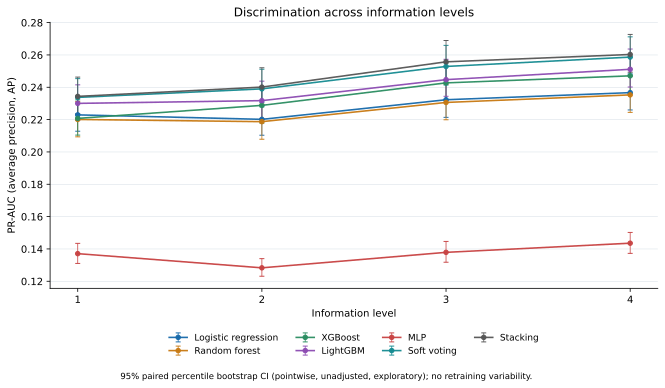

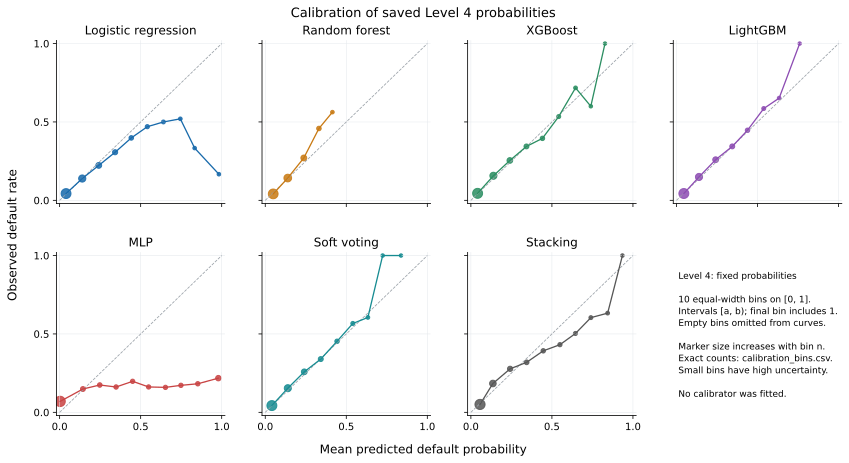

Читаемый отчёт: reports\pilot_20k_5config\evaluation\results_report.html
Текстовый отчёт: reports\pilot_20k_5config\evaluation\results_report.txt
Готовность и ограничения: reports\pilot_20k_5config\evaluation\results_readiness.json
Таблицы CSV/LaTeX: reports\pilot_20k_5config\evaluation\tables
Рисунки PDF/SVG: reports\pilot_20k_5config\evaluation\figures
Новые обучения и новые predict в этом notebook не выполняются.


In [3]:
readiness=export_evaluation_report(PILOT_ROOT,EVALUATION_DIR,previous_reports=PREVIOUS_REPORTS,
                                   create_figures=False)
print('Статус материалов:',readiness.get('status'))
if readiness.get('missing_tables'):
    print('Ещё нет таблиц анализа:',', '.join(readiness['missing_tables']))
else:
    print('Bootstrap-повторов:',readiness.get('completed_bootstrap'))
    print('Готово для предварительного раздела статьи:',readiness.get('ready_for_article'))
    for message in readiness.get('blockers',[]):
        print('Осталось:',message)
    for name,title in [('rq1_level4','RQ1: качество Level 4'),
                       ('rq2_ap_levels','RQ2: AP четырёх уровней'),
                       ('rq2_baseline_gains','RQ2: парные приросты AP относительно L1'),
                       ('profit_fairness_L5','Фиксированный сценарий L/m=5; остальные сценарии в полном отчёте'),
                       ('errors_level4','Ошибки Level 4 при t=0.5')]:
        path=EVALUATION_DIR/'tables'/f'{name}.csv'
        if path.exists():
            print(title)
            display(pd.read_csv(path).fillna('—'))
    mlp_path=EVALUATION_DIR/'mlp_actual_diagnostics.csv'
    if mlp_path.exists():
        print('MLP: фактические эпохи и предупреждения всего search+refit')
        mlp=pd.read_csv(mlp_path)
        display(mlp[['level','n_iter_','max_iter','loss_curve_points','warning_count_search_and_refit']])
    for name in ['ap_by_level','calibration_level4']:
        path=EVALUATION_DIR/'figures'/f'{name}.svg'
        if path.exists():
            display(SVG(filename=str(path)))
    print('Читаемый отчёт:',EVALUATION_DIR/'results_report.html')
    print('Текстовый отчёт:',EVALUATION_DIR/'results_report.txt')
    print('Готовность и ограничения:',EVALUATION_DIR/'results_readiness.json')
    print('Таблицы CSV/LaTeX:',EVALUATION_DIR/'tables')
    print('Рисунки PDF/SVG:',EVALUATION_DIR/'figures')
print('Новые обучения и новые predict в этом notebook не выполняются.')